# Wind forecast error analysis - January 2026

GB national wind: Elexon **WINDFOR** (forecast) vs **FUELHH** `WIND` (outturn).
Scope: forecasts published in January 2026 - i.e. what was available for day-ahead purchase decisions made that month.

Questions this answers for the procurement desk:

1. How accurate is the forecast, and how fast does accuracy decay with horizon?
2. Is the error random, or is there a systematic bias we can correct for?
3. When is the forecast least trustworthy?
4. If we plan on a P10 ("firm") wind number at the day-ahead gate, how often would that have held?
5. How much wind can we actually rely on?

Error convention throughout: **error = forecast − actual** (MW). Positive = over-forecast = we'd have under-bought.

In [1]:
import sys
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "backend"))
from app import analysis
from app.store import load_snapshot

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
store = load_snapshot()
store.coverage

{'targetFrom': '2026-01-01T03:00:00+00:00',
 'targetTo': '2026-02-02T21:00:00+00:00',
 'publishFrom': '2026-01-01T02:30:00+00:00',
 'publishTo': '2026-01-31T22:30:00+00:00',
 'forecastRuns': 248,
 'actualPoints': 1584}

## 1. Build a horizon × target error table

For every hourly target time and every horizon *h* in 0-47h, take the latest forecast published at least *h* hours earlier (capped at 48h) - the same rule the app uses.

In [2]:
START, END = datetime(2026, 1, 1, tzinfo=timezone.utc), datetime(2026, 2, 3, tzinfo=timezone.utc)

rows = []
for h in range(48):
    for r in analysis.compare(store, START, END, h):
        if r["forecast"] is not None:
            rows.append({"h": h, "time": r["time"], "actual": r["actual"], "forecast": r["forecast"],
                         "lead": r["horizonH"], "err": r["error"]})
df = pd.DataFrame(rows)
df["time"] = pd.to_datetime(df["time"], utc=True)
df["abs_err"] = df["err"].abs()
print(f"{len(df):,} (target, horizon) pairs; {df.time.nunique()} target hours")
df.head()

35,698 (target, horizon) pairs; 787 target hours


,h,time,actual,forecast,lead,err,abs_err
0,0,2026-01-01 03:00:00+00:00,14942.0,19907.0,0.5,4965.0,4965.0
1,0,2026-01-01 04:00:00+00:00,15303.0,19673.0,1.5,4370.0,4370.0
2,0,2026-01-01 05:00:00+00:00,15442.0,19574.0,0.5,4132.0,4132.0
3,0,2026-01-01 06:00:00+00:00,15363.0,19554.0,1.5,4191.0,4191.0
4,0,2026-01-01 07:00:00+00:00,15348.0,19612.0,2.5,4264.0,4264.0


## 2. Accuracy vs horizon

,MAE,RMSE,bias,std (bias removed),nMAE %
h,,,,,
0,1731.0,2204.0,1497.0,1619.0,15.0
1,1733.0,2212.0,1495.0,1631.0,15.0
4,1757.0,2240.0,1532.0,1635.0,15.0
12,1796.0,2269.0,1566.0,1643.0,16.0
24,1900.0,2369.0,1664.0,1687.0,17.0
36,2100.0,2616.0,1747.0,1948.0,19.0
47,2352.0,2932.0,1891.0,2246.0,21.0


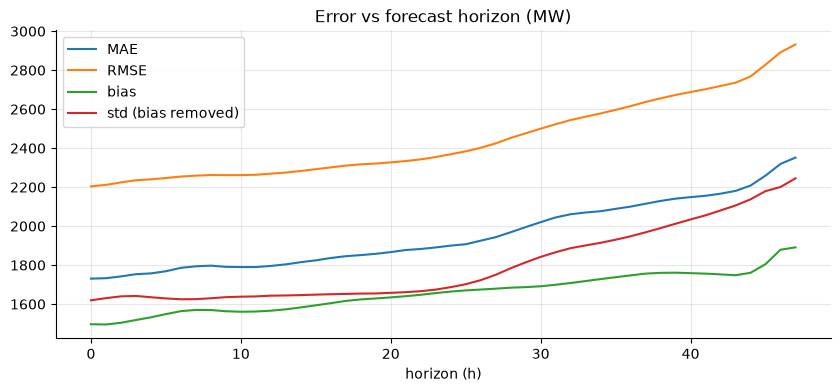

In [3]:
g = df.groupby("h")
by_h = pd.DataFrame({
    "MAE": g.abs_err.mean(),
    "RMSE": g.err.apply(lambda e: np.sqrt((e**2).mean())),
    "bias": g.err.mean(),
    "std (bias removed)": g.err.std(),
    "nMAE %": g.abs_err.mean() / g.actual.mean() * 100,
})
ax = by_h[["MAE", "RMSE", "bias", "std (bias removed)"]].plot(title="Error vs forecast horizon (MW)")
ax.set_xlabel("horizon (h)")
by_h.loc[[0, 1, 4, 12, 24, 36, 47]].round(0)

**Read-out**

* MAE goes from ~1.7 GW at 1h to ~2.3 GW at 47h - roughly 15% → 20% of mean output.
* Most of that error is **bias**, not noise: the forecast sits ~1.5-1.9 GW above outturn on average, at every horizon.
* The bias-free spread (std) is noticeably smaller than MAE, so a simple bias correction should pay off (section 4).

## 3. Where is the error? Wind level, time of day

,n,bias,mae
level,,,
"(0, 2500]",3,222.0,316.0
"(2500, 5000]",35,714.0,1129.0
"(5000, 7500]",79,587.0,1105.0
"(7500, 10000]",135,1140.0,1450.0
"(10000, 12500]",124,1178.0,1371.0
"(12500, 15000]",89,1033.0,1548.0
"(15000, 17500]",102,1701.0,1824.0
"(17500, 20000]",152,2832.0,2832.0
"(20000, 22500]",44,4591.0,4591.0


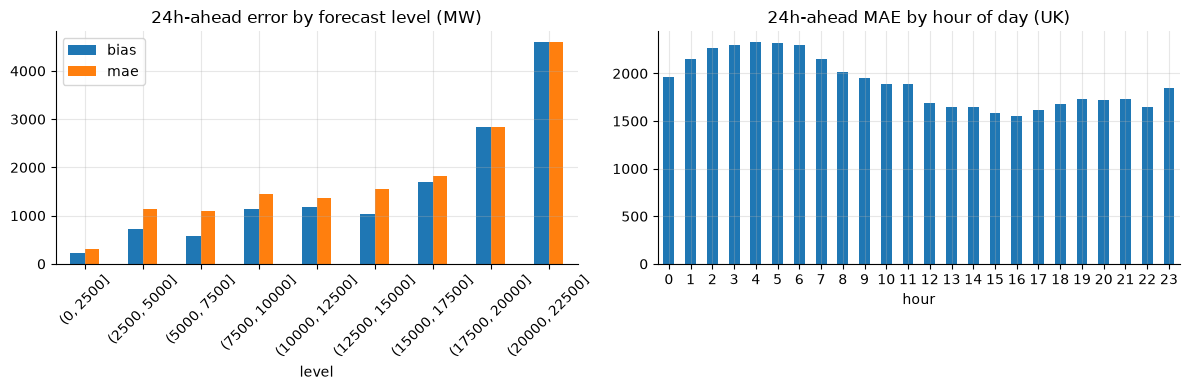

In [4]:
h24 = df[df.h == 24].copy()
h24["level"] = pd.cut(h24.forecast, bins=range(0, 27500, 2500))
lvl = h24.groupby("level", observed=True).agg(n=("err", "size"), bias=("err", "mean"), mae=("abs_err", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lvl[["bias", "mae"]].plot.bar(ax=axes[0], title="24h-ahead error by forecast level (MW)", rot=45)
h24["hour"] = h24.time.dt.tz_convert("Europe/London").dt.hour
h24.groupby("hour").abs_err.mean().plot.bar(ax=axes[1], title="24h-ahead MAE by hour of day (UK)", rot=0)
plt.tight_layout()
lvl.round(0)

**Read-out**

* Over-forecasting grows sharply with forecast level: ~0.5 GW at low wind, **>4 GW when ≥20 GW is forecast**.
  The likely driver is **curtailment**: FUELHH is *metered* output after the System Operator turns wind down to manage
  transmission constraints (mostly Scottish wind on windy days), while WINDFOR forecasts the wind resource. That's a
  structural gap, not a bad weather model - and it's predictable.
* Overnight / early-morning hours carry slightly higher error than the afternoon.

## 4. Can a simple bias correction help? (out-of-sample)

For each target, subtract the mean error observed over the **previous 7 days** at the same horizon (only errors whose target time has already passed - no look-ahead).

In [5]:
def corrected(h, window_days=7):
    d = df[df.h == h].sort_values("time").set_index("time")
    roll = d.err.rolling(f"{window_days}D").mean()
    # forecast for t is issued at t-h, so only errors for targets <= t-h-1 are known by then
    known = roll.reindex(d.index - pd.Timedelta(hours=h + 1), method="ffill")
    d["fc_adj"] = d.forecast - pd.Series(known.values, index=d.index).fillna(0)
    d["err_adj"] = d.fc_adj - d.actual
    d = d[d.index >= d.index.min() + pd.Timedelta(days=window_days)]
    return d

res = []
for h in [1, 4, 12, 24, 36]:
    d = corrected(h)
    res.append({"h": h, "MAE raw": d.err.abs().mean(), "MAE bias-corrected": d.err_adj.abs().mean(),
                "bias raw": d.err.mean(), "bias corrected": d.err_adj.mean()})
res = pd.DataFrame(res).set_index("h")
res["improvement %"] = (1 - res["MAE bias-corrected"] / res["MAE raw"]) * 100
res.round(0)

,MAE raw,MAE bias-corrected,bias raw,bias corrected,improvement %
h,,,,,
1,1686.0,1232.0,1590.0,53.0,27.0
4,1715.0,1246.0,1618.0,42.0,27.0
12,1759.0,1371.0,1587.0,20.0,22.0
24,1938.0,1454.0,1735.0,38.0,25.0
36,2240.0,1785.0,1909.0,143.0,20.0


**Read-out** - a trailing-week bias adjustment is a cheap, transparent post-processing step that removes most of the systematic
over-forecast. It's the obvious next feature for the product (one toggle: *raw / bias-adjusted*).
The trailing bias only uses errors for targets that had already happened when each forecast was issued, so this is a fair backtest.

## 5. Day-ahead backtest - would a P10 plan have held?

For every delivery day 2 Jan … 1 Feb: take the forecast as of 11:00 UK on D-1, build the P10-P90 band from errors observable before the gate, and check the outcome.

days: 31, out-of-sample: 29
hours inside P10-P90 (target 80%): 74%
hours below P10      (target 10%): 12%
days where daily actual energy < P10 energy: 3 / 29


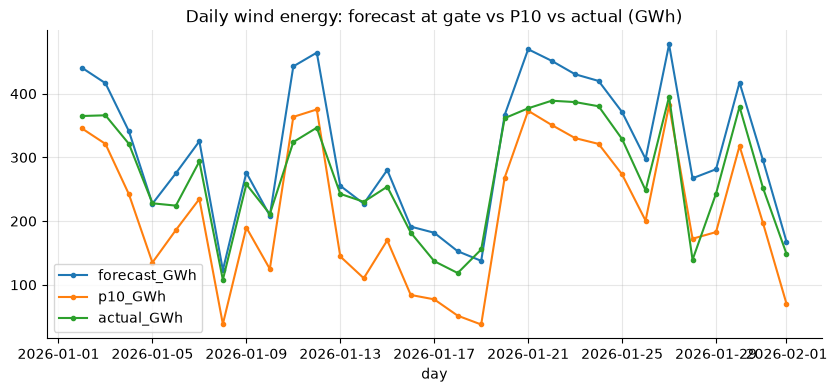

In [6]:
bt = []
day = date(2026, 1, 2)
while day <= date(2026, 2, 1):
    r = analysis.day_ahead(store, day)
    s = r["summary"]
    if "actualEnergyMWh" in s and r["band"]:
        pts = [p for p in r["points"] if p["forecast"] is not None and p["actual"] is not None]
        bt.append({
            "day": day, "calibration": r["band"]["calibration"],
            "forecast_GWh": s["forecastEnergyMWh"] / 1e3, "p10_GWh": s["p10EnergyMWh"] / 1e3,
            "actual_GWh": s["actualEnergyMWh"] / 1e3, "band_hit": s["bandHitRate"],
            "below_p10": np.mean([p["actual"] < p["p10"] for p in pts]),
        })
    day += timedelta(days=1)
bt = pd.DataFrame(bt).set_index("day")
oos = bt[bt.calibration == "out-of-sample"]
print(f"days: {len(bt)}, out-of-sample: {len(oos)}")
print(f"hours inside P10-P90 (target 80%): {oos.band_hit.mean():.0%}")
print(f"hours below P10      (target 10%): {oos.below_p10.mean():.0%}")
print(f"days where daily actual energy < P10 energy: {(oos.actual_GWh < oos.p10_GWh).sum()} / {len(oos)}")
ax = bt[["forecast_GWh", "p10_GWh", "actual_GWh"]].plot(title="Daily wind energy: forecast at gate vs P10 vs actual (GWh)", marker=".")

**Read-out** - the empirical band is roughly calibrated hour-by-hour, and the P10 daily energy is a conservative
planning number: daily actual wind energy fell below it on only a handful of days. Planning on raw forecast would have left the desk short on
most days because of the bias above.

## 6. How much wind can we rely on?

P5      4.3 GW
P10     5.6 GW
P25     8.2 GW
P50    12.1 GW
P75    15.3 GW
P90    16.4 GW
dtype: str


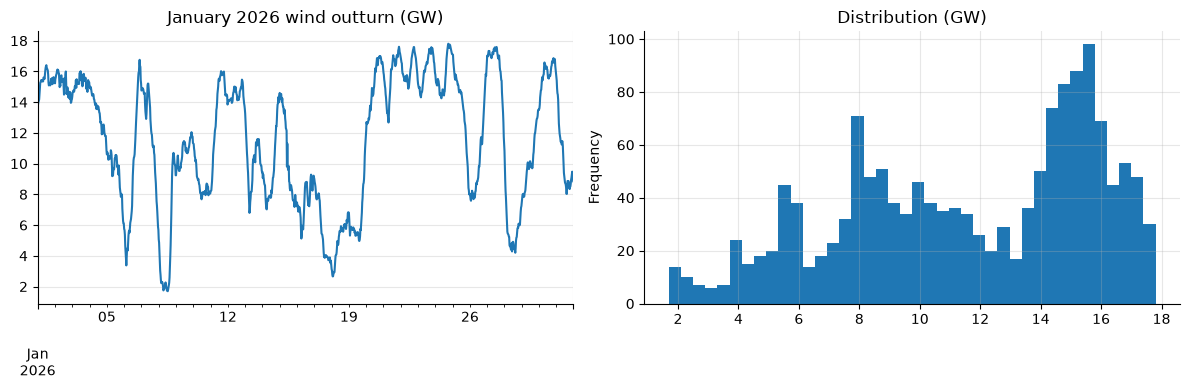

In [7]:
act = pd.Series(store.actuals).sort_index()
act = act[(act.index >= START) & (act.index < datetime(2026, 2, 1, tzinfo=timezone.utc))]
q = act.quantile([0.05, 0.1, 0.25, 0.5, 0.75, 0.9]).rename(lambda x: f"P{int(x*100)}")
print((q / 1000).round(1).astype(str) + " GW")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(act / 1000).plot(ax=axes[0], title="January 2026 wind outturn (GW)")
(act / 1000).plot.hist(bins=40, ax=axes[1], title="Distribution (GW)")
plt.tight_layout()

## Conclusions for the desk

1. **The raw forecast is biased high** (~1.5-2 GW in January) and the bias grows with wind level - most likely curtailment. Treat the
   raw number as an upper-ish estimate, not a central one.
2. **Horizon matters less than bias.** Going from 1h to 24h ahead adds only ~10% to MAE; the day-ahead forecast is almost as good as
   a same-day one - the gain is in correcting the bias.
3. **Plan on the P10, not the forecast.** At the 11:00 gate, the empirical P10 band gives a firm-wind number that held in ~88% of
   hours (target 90%); the gap between forecast and P10 is the volume to consider hedging.
4. **Reliability:** wind delivered < ~5.6 GW in 10% of January's half-hours (P10 of outturn) - that floor is all that can be considered
   "always there" for the month.

**Limitations:** one month of data; national level only; no demand, price or curtailment data was used (out of scope) - these are
the obvious next steps.